#### Importing Required Libraries

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

#### Dataset Loading and Initial Inspection

In [39]:
df = pd.read_csv('pipeline_corrosion.csv')
df.head()

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
0,SEG-0001,2005-01-01,1,2.00,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,NaN,NaN,0.001000,NaN,7017.44,439.00,-0.15288,730.5000,NaN
1,SEG-0001,2006-01-24,2,3.06,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.014,0.075545,0.001750,0.0015,7813.26,664.62,1.54336,1140.6650,388.0
2,SEG-0001,2007-01-06,3,4.01,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.061,0.328912,0.001500,-0.0015,7071.12,2976.00,0.57552,1469.6525,347.0
3,SEG-0001,2007-12-24,4,4.98,X52,609.6,18.63,FBE,1,wet_gas,...,0.0010,0.020,0.107486,0.003667,0.0065,6672.00,1904.00,0.19257,2175.9450,352.0
4,SEG-0001,2008-11-26,5,5.90,X52,609.6,18.63,FBE,1,wet_gas,...,0.0025,-0.076,-0.408010,0.003167,-0.0065,5190.30,2038.11,0.29480,2484.9750,338.0


In [40]:
df.shape

(8440, 48)

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8440 entries, 0 to 8439
Data columns (total 48 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   segment_id                    8440 non-null   object 
 1   measurement_date              8440 non-null   object 
 2   measurement_num               8440 non-null   int64  
 3   age_years                     8440 non-null   float64
 4   material                      8440 non-null   object 
 5   diameter_mm                   8440 non-null   float64
 6   nominal_thickness_mm          8440 non-null   float64
 7   coating_type                  8440 non-null   object 
 8   cathodic_protection           8440 non-null   int64  
 9   fluid_type                    8440 non-null   object 
 10  corrosion_mechanism           8440 non-null   object 
 11  seam_type                     8440 non-null   object 
 12  temperature_c                 8440 non-null   float64
 13  pre

In [42]:
df.describe()

,measurement_num,age_years,diameter_mm,nominal_thickness_mm,cathodic_protection,temperature_c,pressure_bar,flow_rate_m3h,pH,co2_partial_pressure_bar,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
count,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,...,7690.000000,8190.000000,8190.000000,8440.000000,8190.000000,8440.000000,8440.000000,8440.000000,8440.000000,8190.000000
mean,22.633649,16.801977,385.481671,10.105521,0.681754,69.417583,52.126742,247.503886,5.480473,2.544147,...,3.796439,-0.040497,0.066627,3.757358,-0.021472,3600.692977,13797.210873,3.789854,6316.725240,188.989255
std,16.567604,9.809462,205.075696,4.101488,0.465823,32.070074,28.562783,141.834829,1.117903,1.489995,...,8.451238,0.278374,14.930606,8.358461,1.725232,2686.115854,10711.262026,3.937311,3592.451361,119.231892
min,1.000000,0.000000,114.300000,2.810000,0.000000,5.000000,1.000000,1.000000,2.790000,0.000000,...,0.001000,-8.366000,-94.863363,0.001000,-24.966800,6.930000,0.000000,-5.113500,0.000000,60.000000
25%,9.000000,8.690000,219.100000,6.580000,0.000000,44.900000,29.200000,130.800000,4.610000,1.234750,...,0.006100,-0.124000,-1.914174,0.005858,-0.007200,1509.712500,5855.500000,0.648672,3338.192500,121.000000
50%,19.000000,16.530000,323.900000,9.760000,1.000000,67.200000,49.500000,244.000000,5.470000,2.524000,...,0.025200,-0.020000,-0.276258,0.025350,0.000000,2907.555000,10539.470000,2.760465,6209.250000,155.000000
75%,33.000000,24.332500,609.600000,12.530000,1.000000,94.600000,77.900000,370.050000,6.340000,3.946000,...,0.276725,0.077000,1.110299,0.284658,0.006800,5275.472500,20599.305000,6.294263,9064.846250,207.000000
max,82.000000,39.990000,762.000000,23.500000,1.000000,181.200000,109.900000,553.700000,8.160000,5.467000,...,25.015200,0.507000,169.000000,25.008700,24.803100,13381.760000,52219.200000,19.463400,14968.347500,746.000000


In [43]:
df.nunique()

segment_id                       250
measurement_date                4866
measurement_num                   82
age_years                       3280
material                           6
diameter_mm                        9
nominal_thickness_mm             225
coating_type                       4
cathodic_protection                2
fluid_type                         5
corrosion_mechanism                6
seam_type                          3
temperature_c                   1369
pressure_bar                    1028
flow_rate_m3h                   4111
pH                               496
co2_partial_pressure_bar        4059
h2s_ppm                         4068
water_cut_pct                    982
inhibitor_dose_ppm              2368
chloride_ppm                    4122
dissolved_o2_ppb                 590
coating_condition                571
measured_thickness_mm           5638
corrosion_rate_mm_yr            2615
cumulative_thickness_loss_mm    3375
normalized_thickness            2870
r

In [44]:
df.duplicated().sum()

np.int64(0)

#### Exploratory Data Analysis (EDA

In [45]:
features = ['segment_id', 'measurement_date','age_years','material','diameter_mm','nominal_thickness_mm','coating_type','cathodic_protection','fluid_type','corrosion_mechanism','seam_type','temperature_c',
'pressure_bar','flow_rate_m3h','pH','co2_partial_pressure_bar','h2s_ppm','water_cut_pct','inhibitor_dose_ppm','chloride_ppm','dissolved_o2_ppb','coating_condition','measured_thickness_mm',
'corr_rate_lag_1','thickness_lag_1', 'corr_rate_lag_2','corrosion_rate_mm_yr']

In [46]:
df1=df[features]

In [47]:
df1.shape

(8440, 27)

In [48]:
numerical_columns=df1.select_dtypes(include=np.number).columns
catogorical_columns=df1.select_dtypes(include=['object','category']).columns

In [49]:
numerical_columns

Index(['age_years', 'diameter_mm', 'nominal_thickness_mm',
       'cathodic_protection', 'temperature_c', 'pressure_bar', 'flow_rate_m3h',
       'pH', 'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corr_rate_lag_1',
       'thickness_lag_1', 'corr_rate_lag_2', 'corrosion_rate_mm_yr'],
      dtype='object')

In [50]:
catogorical_columns

Index(['segment_id', 'measurement_date', 'material', 'coating_type',
       'fluid_type', 'corrosion_mechanism', 'seam_type'],
      dtype='object')

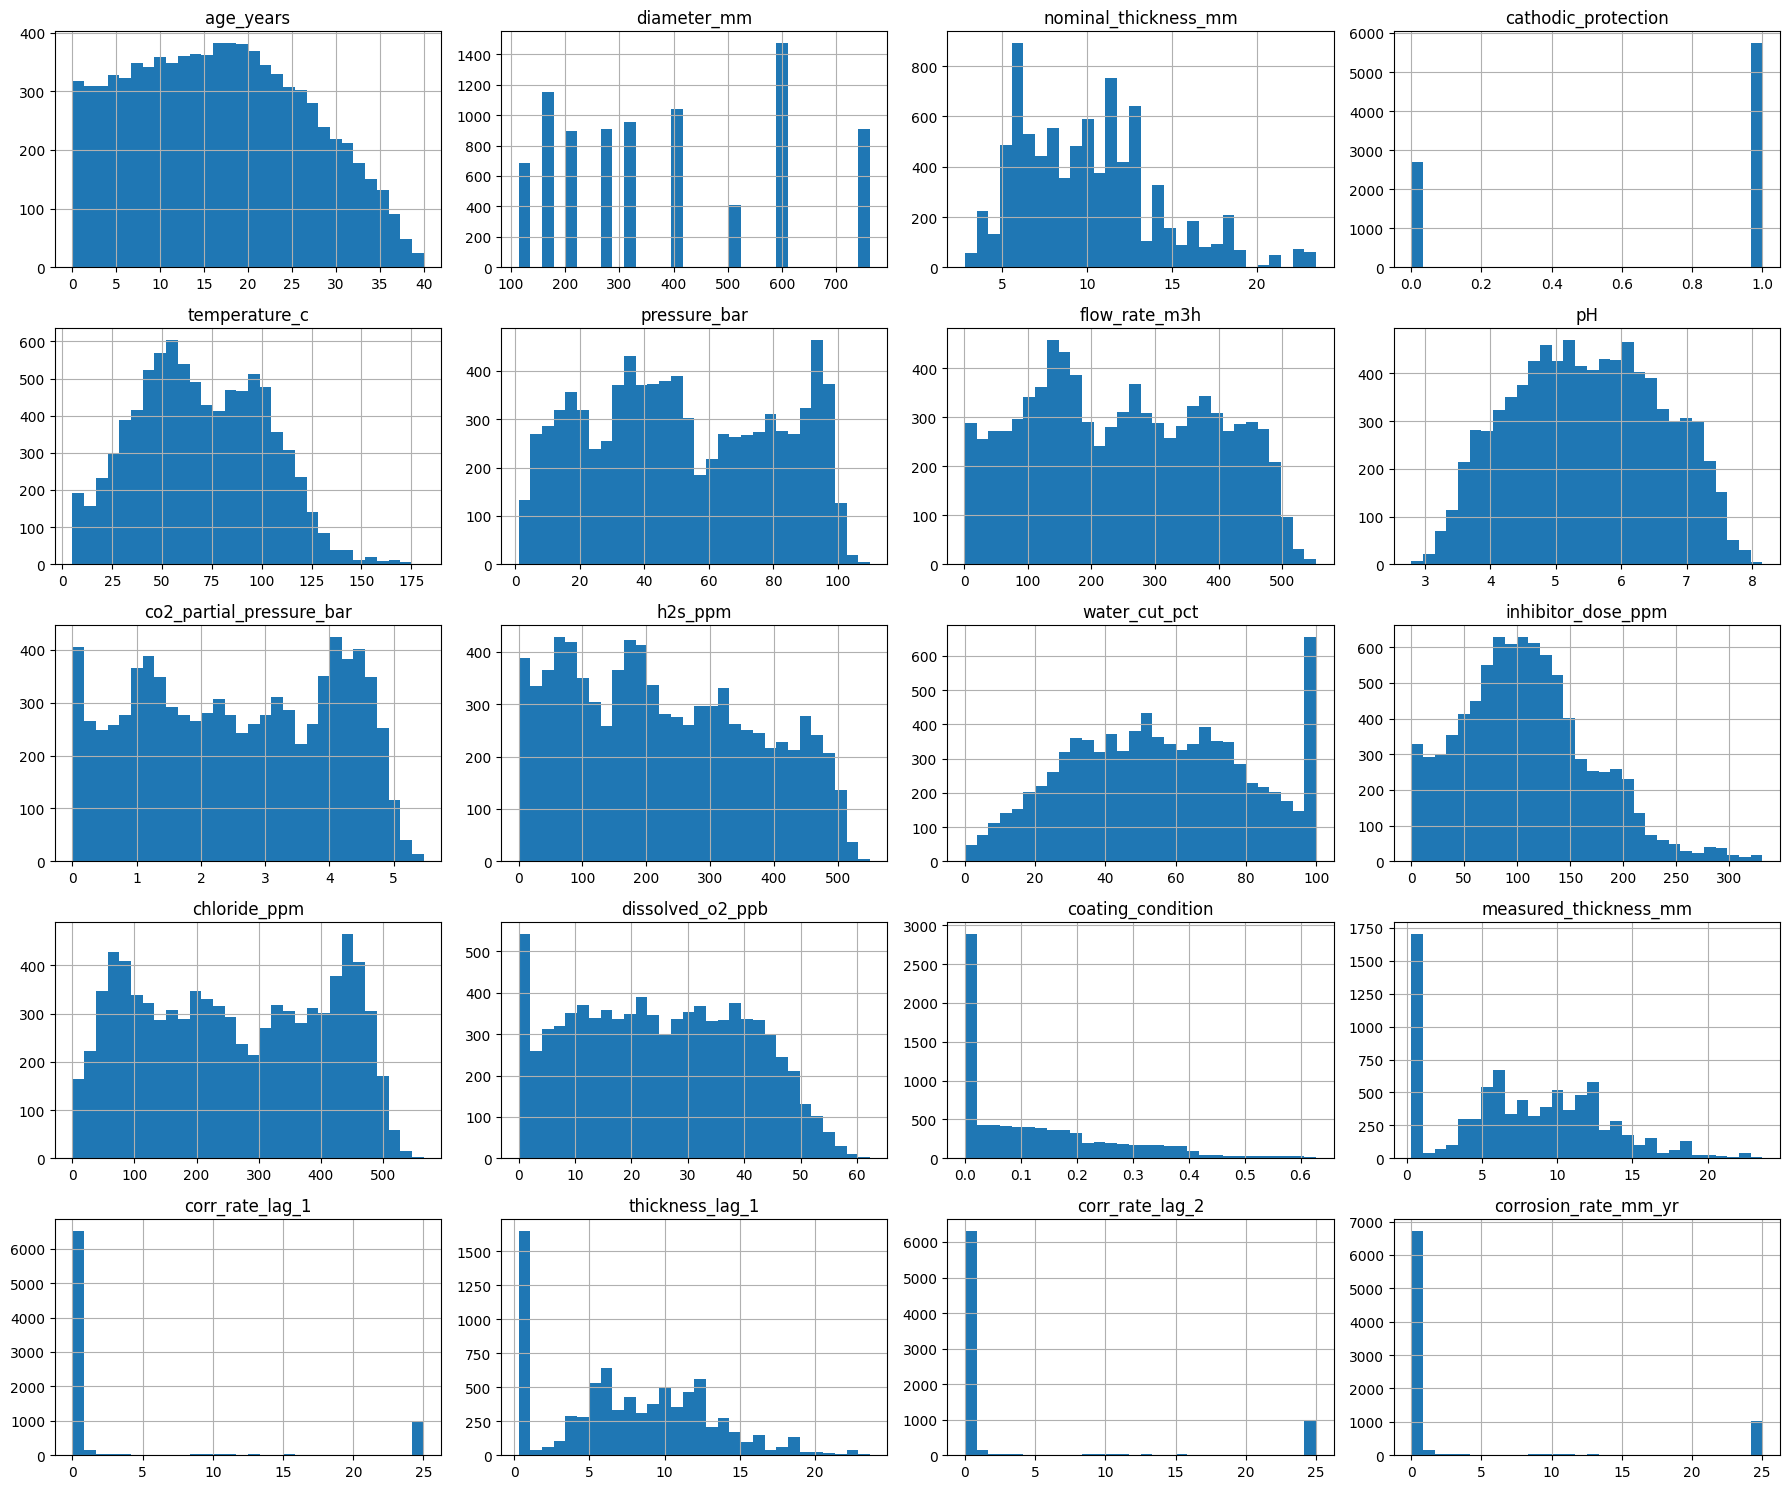

In [51]:
df1[numerical_columns].hist(figsize=(18, 15),bins=30)
plt.tight_layout()
plt.show()

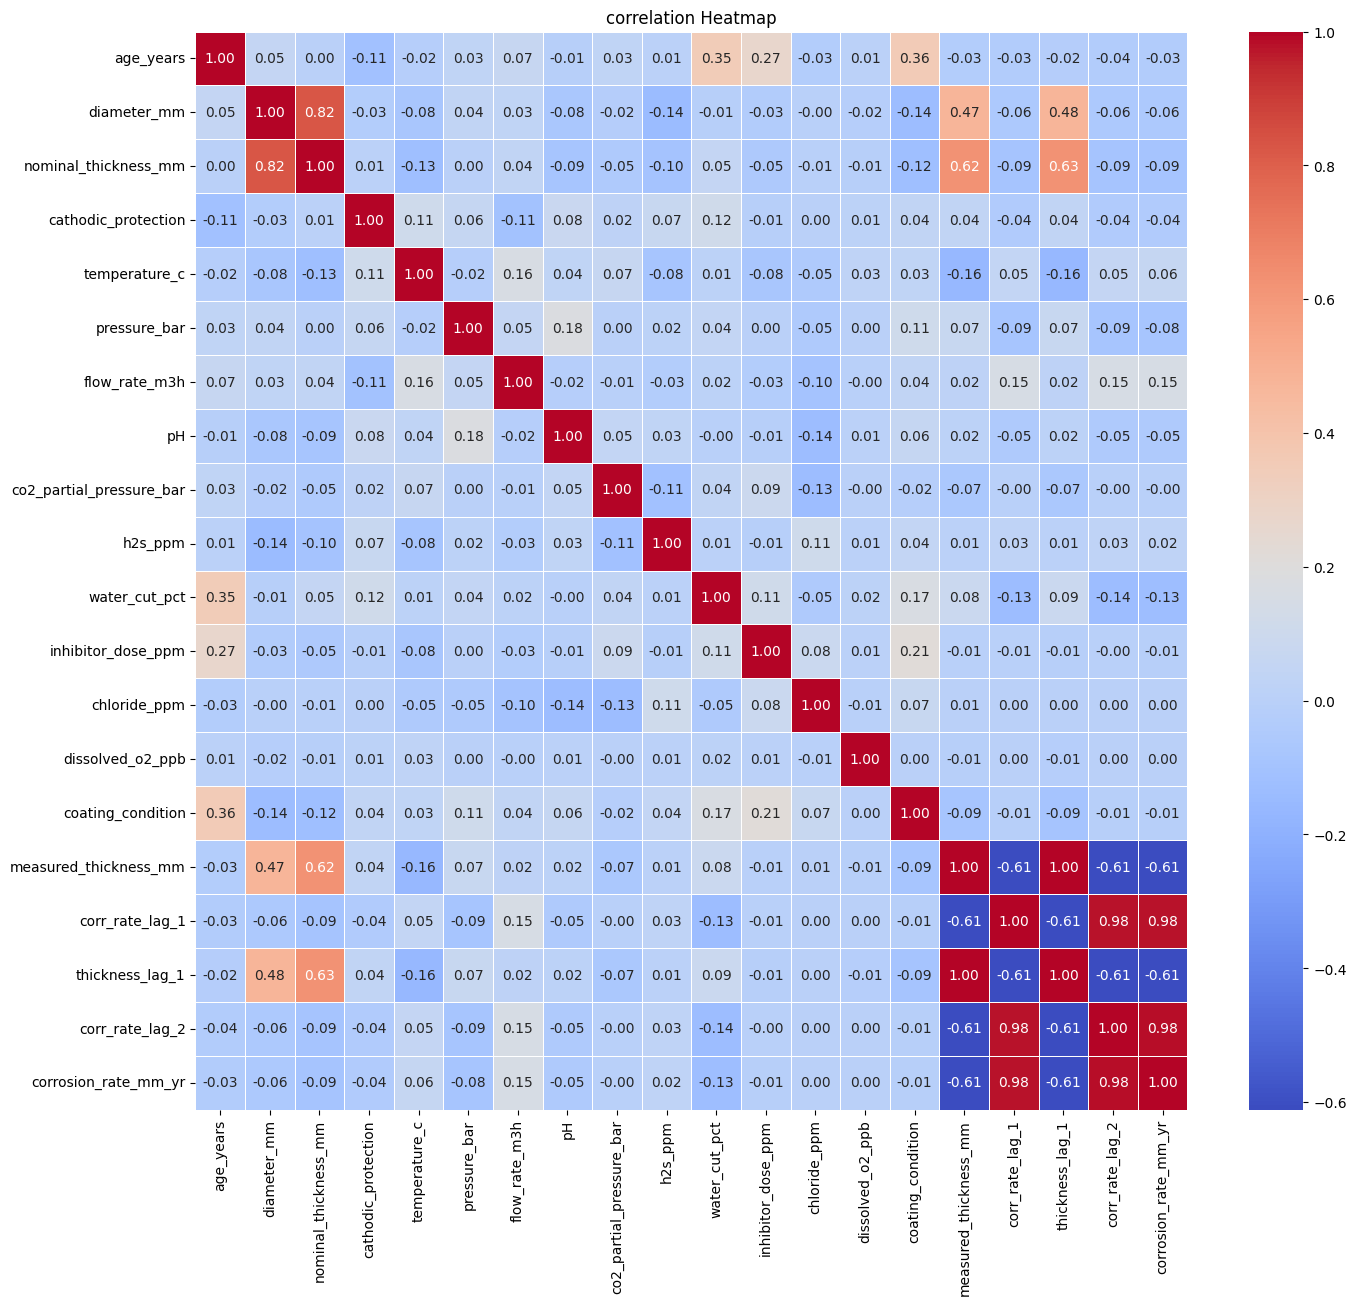

In [52]:
correlation=df1[numerical_columns].corr()
plt.figure(figsize=(16,14))
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('correlation Heatmap')
plt.show()

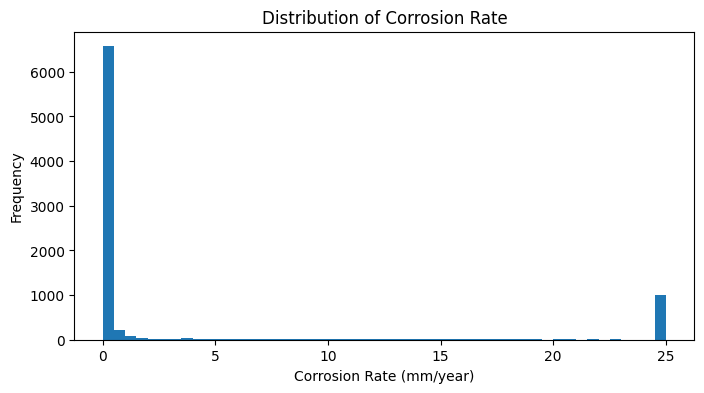

In [53]:
plt.figure(figsize=(8, 4))
plt.hist(df1['corrosion_rate_mm_yr'], bins=50)
plt.xlabel('Corrosion Rate (mm/year)')
plt.ylabel('Frequency')
plt.title('Distribution of Corrosion Rate')
plt.show()

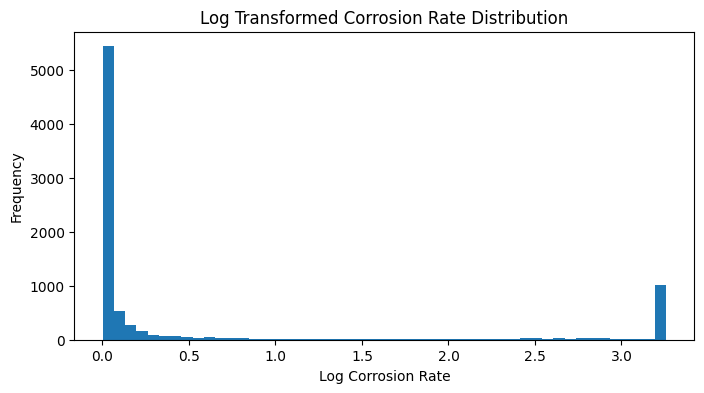

In [54]:
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(df1['corrosion_rate_mm_yr']),bins=50)
plt.xlabel('Log Corrosion Rate')
plt.ylabel('Frequency')
plt.title('Log Transformed Corrosion Rate Distribution')
plt.show()

In [55]:
df1.isnull().sum()

segment_id                    0
measurement_date              0
age_years                     0
material                      0
diameter_mm                   0
nominal_thickness_mm          0
coating_type                  0
cathodic_protection           0
fluid_type                    0
corrosion_mechanism           0
seam_type                     0
temperature_c                 0
pressure_bar                  0
flow_rate_m3h                 0
pH                            0
co2_partial_pressure_bar      0
h2s_ppm                       0
water_cut_pct                 0
inhibitor_dose_ppm            0
chloride_ppm                  0
dissolved_o2_ppb              0
coating_condition             0
measured_thickness_mm         0
corr_rate_lag_1             250
thickness_lag_1             250
corr_rate_lag_2             500
corrosion_rate_mm_yr          0
dtype: int64

In [72]:
missing = pd.DataFrame({
    "Missing_Count": df1.isnull().sum(),
    "Missing_Percentage": df1.isnull().mean() * 100
})

print(missing[missing["Missing_Count"] > 0])

                 Missing_Count  Missing_Percentage
corr_rate_lag_1            250            2.962085
thickness_lag_1            250            2.962085
corr_rate_lag_2            500            5.924171


In [73]:
lag_cols = ['corr_rate_lag_1','thickness_lag_1','corr_rate_lag_2']

In [74]:
df_clean = df1.dropna(subset=lag_cols).copy()

In [75]:
print("Original shape:", df1.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (8440, 27)
Cleaned shape: (7940, 27)


In [60]:
num_cols = df_clean.select_dtypes(include=np.number).columns
print(num_cols)

Index(['age_years', 'diameter_mm', 'nominal_thickness_mm',
       'cathodic_protection', 'temperature_c', 'pressure_bar', 'flow_rate_m3h',
       'pH', 'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corr_rate_lag_1',
       'thickness_lag_1', 'corr_rate_lag_2', 'corrosion_rate_mm_yr'],
      dtype='object')


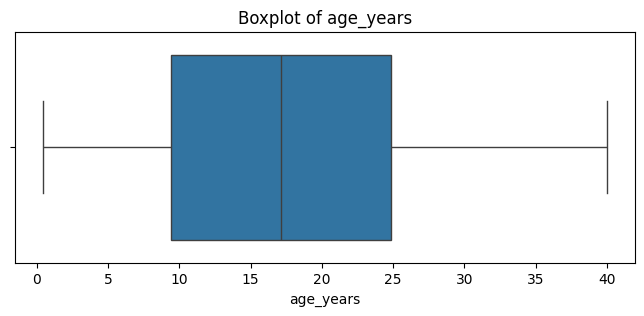

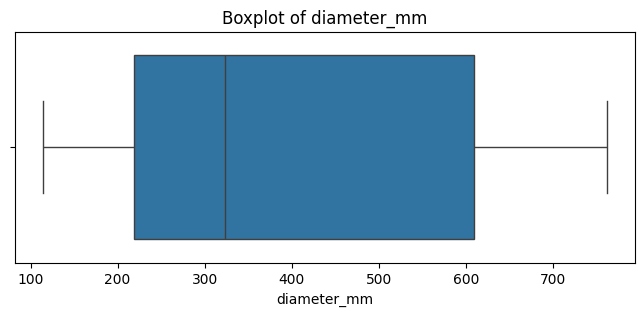

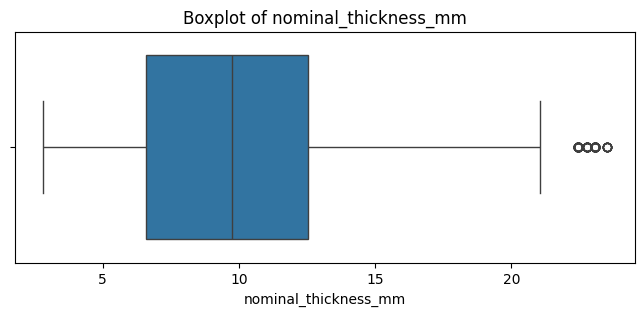

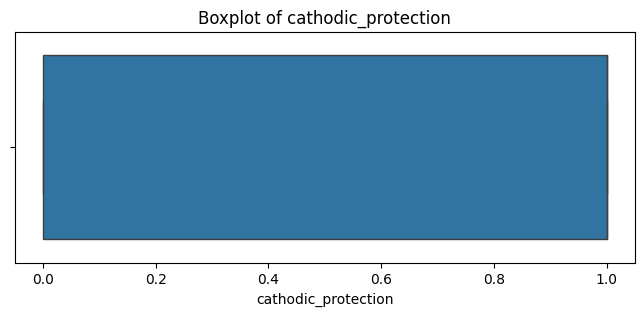

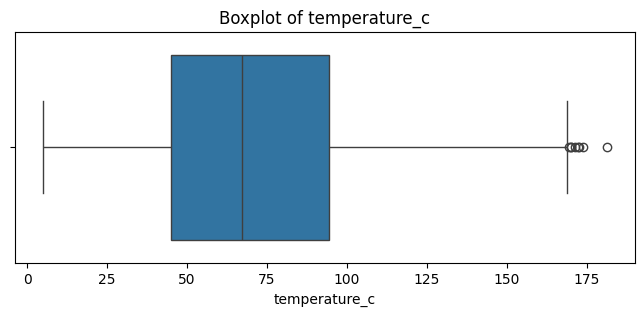

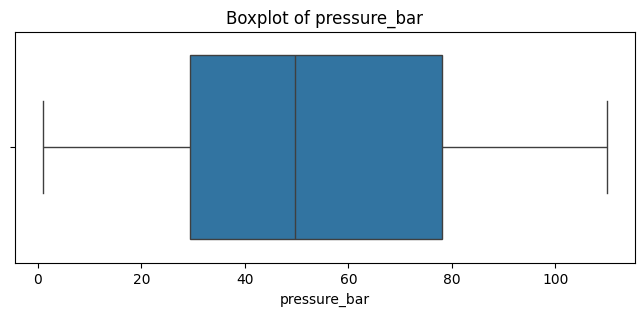

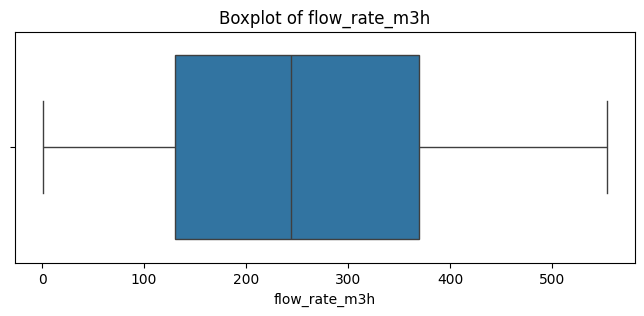

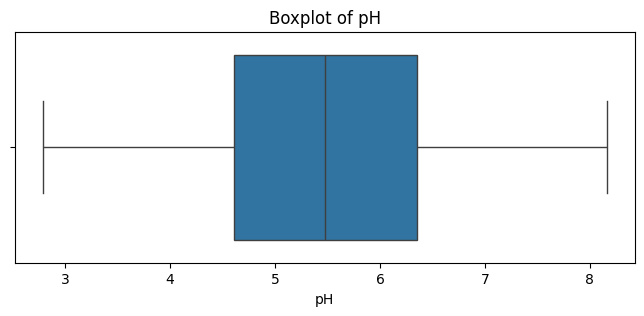

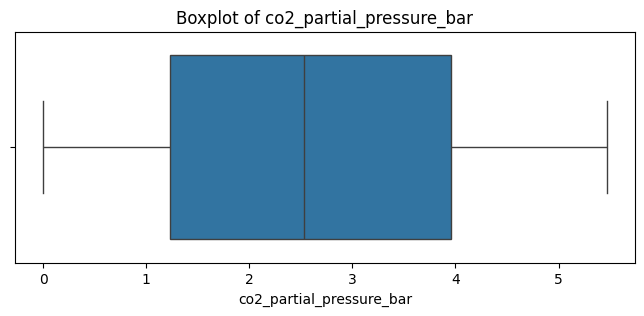

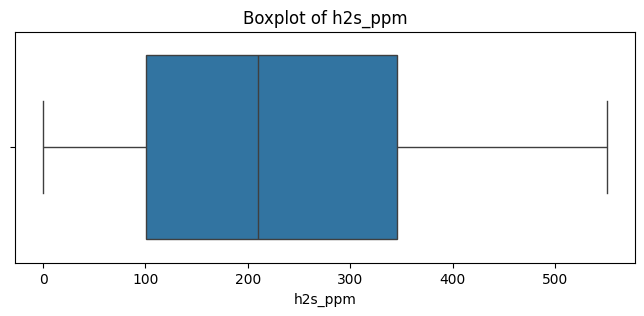

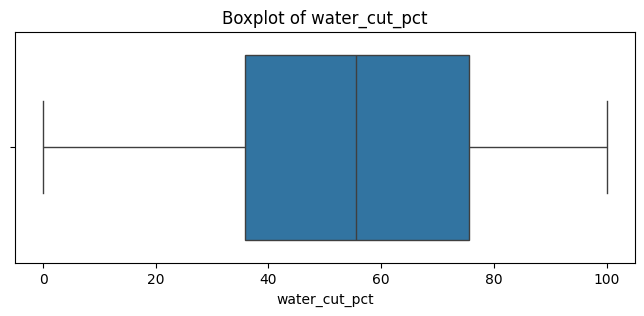

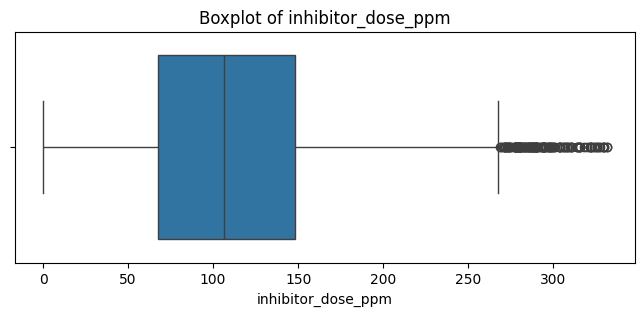

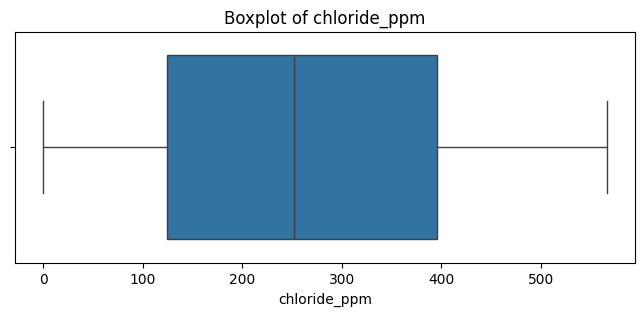

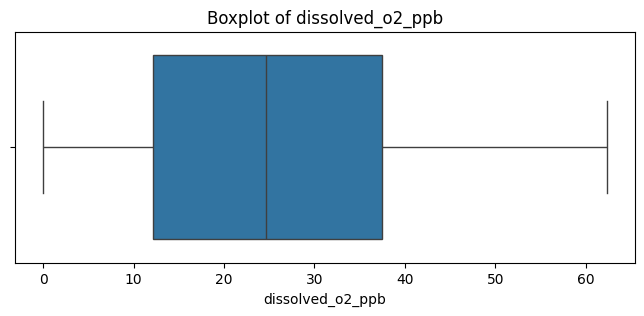

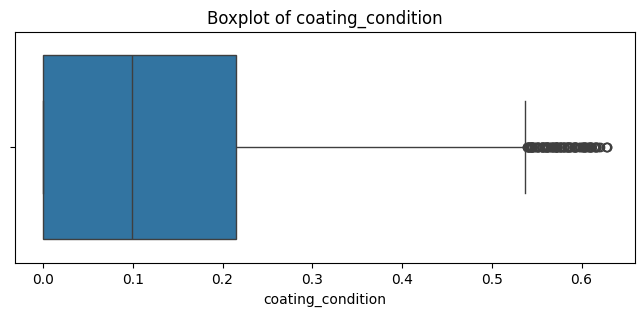

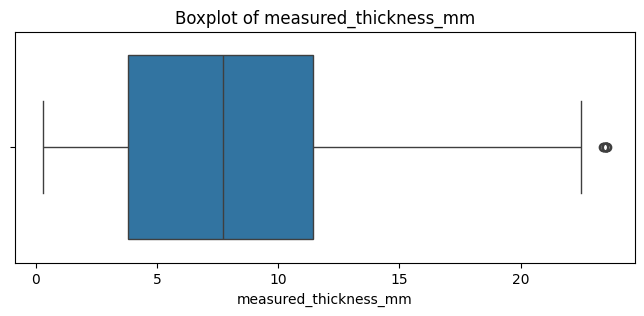

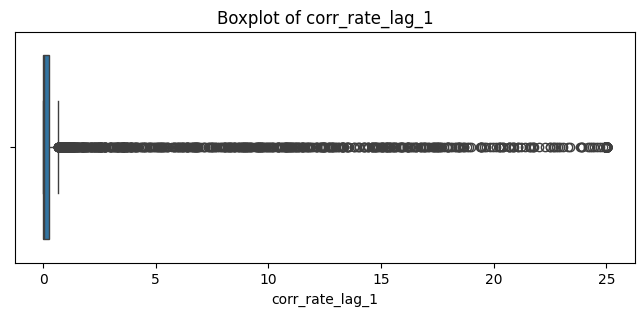

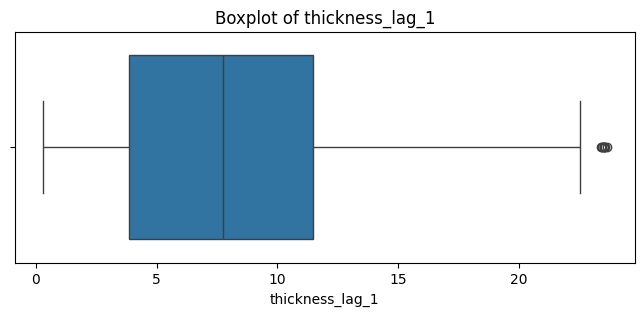

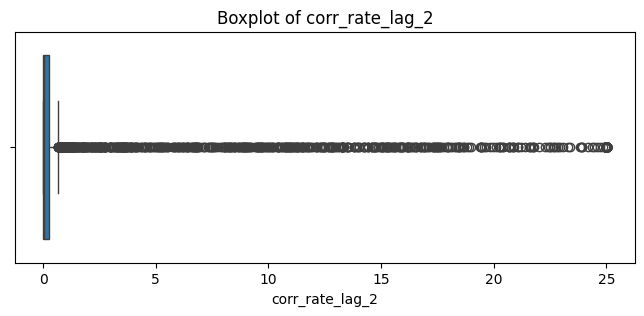

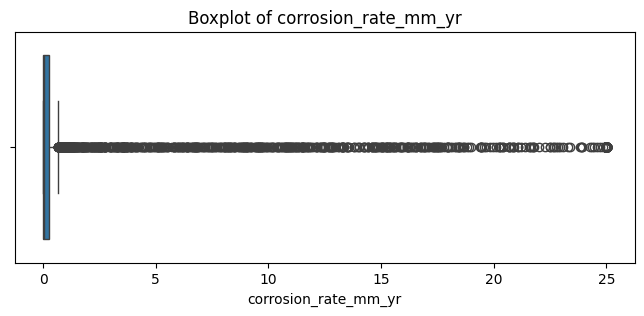

In [61]:
for col in numerical_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df_clean[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [62]:
for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df_clean[col] < lower) |
             (df_clean[col] > upper)).sum()

    print(col, ":", count)

age_years : 0
diameter_mm : 0
nominal_thickness_mm : 125
cathodic_protection : 0
temperature_c : 8
pressure_bar : 0
flow_rate_m3h : 0
pH : 0
co2_partial_pressure_bar : 0
h2s_ppm : 0
water_cut_pct : 0
inhibitor_dose_ppm : 142
chloride_ppm : 0
dissolved_o2_ppb : 0
coating_condition : 117
measured_thickness_mm : 8
corr_rate_lag_1 : 1677
thickness_lag_1 : 8
corr_rate_lag_2 : 1676
corrosion_rate_mm_yr : 1672


In [63]:
check_cols = [
    'nominal_thickness_mm',
    'inhibitor_dose_ppm',
    'coating_condition',
    'corr_rate_lag_1',
    'corr_rate_lag_2',
    'corrosion_rate_mm_yr'
]

for col in check_cols:
    print("\n", col)
    print(df_clean[col].describe())


 nominal_thickness_mm
count    7940.000000
mean       10.110710
std         4.097929
min         2.810000
25%         6.580000
50%         9.760000
75%        12.530000
max        23.500000
Name: nominal_thickness_mm, dtype: float64

 inhibitor_dose_ppm
count    7940.000000
mean      111.269887
std        62.116584
min         0.000000
25%        67.675000
50%       106.350000
75%       147.900000
max       331.400000
Name: inhibitor_dose_ppm, dtype: float64

 coating_condition
count    7940.000000
mean        0.135119
std         0.141256
min         0.000000
25%         0.000000
50%         0.099000
75%         0.215000
max         0.628000
Name: coating_condition, dtype: float64

 corr_rate_lag_1
count    7940.000000
mean        3.762072
std         8.410747
min         0.001000
25%         0.005900
50%         0.024650
75%         0.271225
max        25.015200
Name: corr_rate_lag_1, dtype: float64

 corr_rate_lag_2
count    7940.000000
mean        3.779124
std         8.432565
min

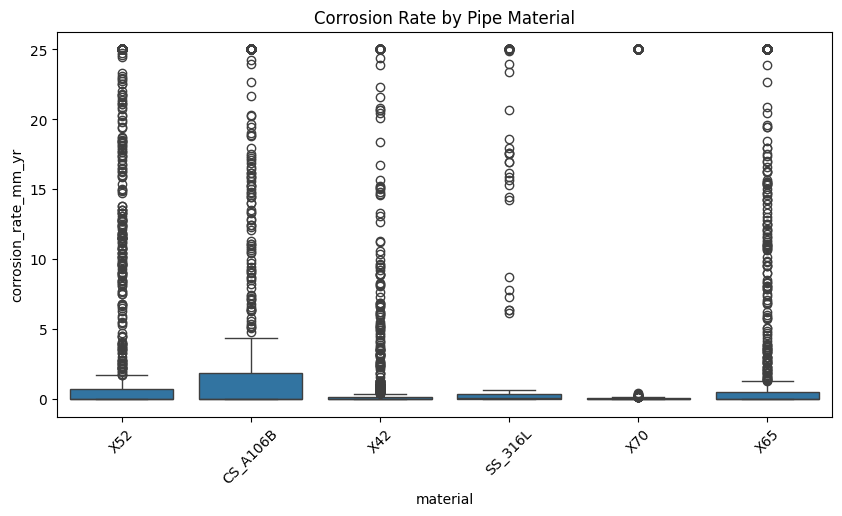

In [64]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x='material',
    y='corrosion_rate_mm_yr'
)

plt.title('Corrosion Rate by Pipe Material')
plt.xticks(rotation=45)
plt.show()

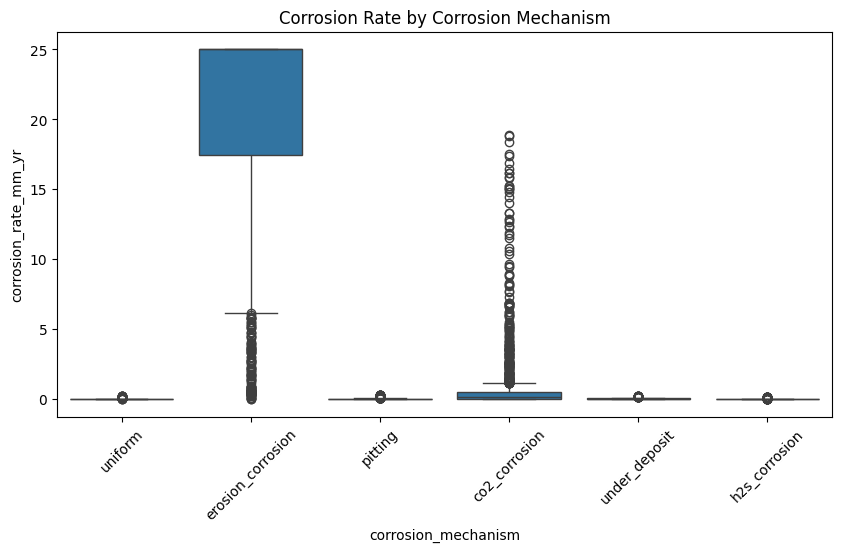

In [65]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean,x='corrosion_mechanism',y='corrosion_rate_mm_yr')
plt.title('Corrosion Rate by Corrosion Mechanism')
plt.xticks(rotation=45)
plt.show()

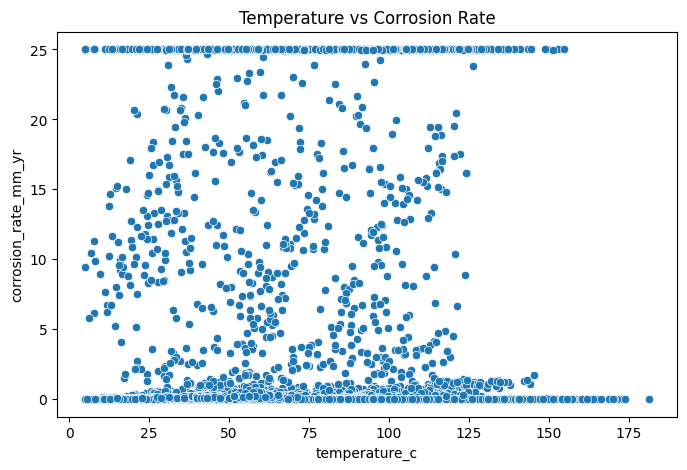

In [66]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean,x='temperature_c',y='corrosion_rate_mm_yr')
plt.title('Temperature vs Corrosion Rate')
plt.show()

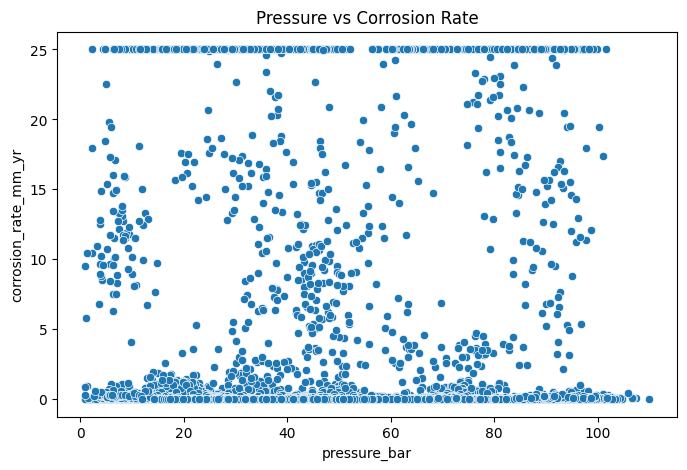

In [67]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean,x='pressure_bar',y='corrosion_rate_mm_yr')
plt.title('Pressure vs Corrosion Rate')
plt.show()

#### Preprocessing

In [68]:
df_clean = df.copy()
print("Dataset shape:", df_clean.shape)

Dataset shape: (8440, 48)


In [69]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [80]:
missing = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing %": df_clean.isnull().mean() * 100
})

missing[missing["Missing Count"] > 0]

,Missing Count,Missing %


In [81]:
target = "corrosion_rate_mm_yr"

print(df_clean[target].describe())

count    7940.000000
mean        3.746057
std         8.393406
min         0.001000
25%         0.005800
50%         0.024300
75%         0.270650
max        25.015200
Name: corrosion_rate_mm_yr, dtype: float64


In [82]:
correlation = df_clean[num_cols].corr()

correlation['corrosion_rate_mm_yr'].sort_values(
    ascending=False
)

corrosion_rate_mm_yr        1.000000
corr_rate_lag_2             0.984598
corr_rate_lag_1             0.978638
flow_rate_m3h               0.157692
temperature_c               0.058789
h2s_ppm                     0.027307
chloride_ppm                0.002616
dissolved_o2_ppb            0.001909
co2_partial_pressure_bar   -0.005834
coating_condition          -0.010046
inhibitor_dose_ppm         -0.010240
age_years                  -0.035531
cathodic_protection        -0.043984
pH                         -0.048902
diameter_mm                -0.061611
pressure_bar               -0.085891
nominal_thickness_mm       -0.094649
water_cut_pct              -0.136778
measured_thickness_mm      -0.606834
thickness_lag_1            -0.608354
Name: corrosion_rate_mm_yr, dtype: float64

In [84]:
X = df_clean.drop(columns=[target, 'segment_id', 'measurement_date'])

y = df_clean[target]

In [85]:
print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(X.isnull().sum().sort_values(ascending=False).head(15))

print("\nSelected features:")
print(X.columns.tolist())

print("\nTarget:")
print(target)

Final dataset shape: (7940, 27)

Missing values:
age_years                   0
material                    0
diameter_mm                 0
nominal_thickness_mm        0
coating_type                0
cathodic_protection         0
fluid_type                  0
corrosion_mechanism         0
seam_type                   0
temperature_c               0
pressure_bar                0
flow_rate_m3h               0
pH                          0
co2_partial_pressure_bar    0
h2s_ppm                     0
dtype: int64

Selected features:
['age_years', 'material', 'diameter_mm', 'nominal_thickness_mm', 'coating_type', 'cathodic_protection', 'fluid_type', 'corrosion_mechanism', 'seam_type', 'temperature_c', 'pressure_bar', 'flow_rate_m3h', 'pH', 'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct', 'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb', 'coating_condition', 'measured_thickness_mm', 'corr_rate_lag_1', 'thickness_lag_1', 'corr_rate_lag_2']

Target:
corrosion_rate_mm_yr


In [86]:
df.to_csv("pipeline_corrosion.csv", index=False)